In [1]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


In [2]:
sgc_pop = populations.SGC()
pyr_pop = populations.Pyramidal()
ds_pop = populations.DStellate()
vert_pop = populations.Tuberculoventral()

sgc_cfs = sgc_pop._get_cf_array(species='mouse')
pyr_cfs = pyr_pop._get_cf_array(species='mouse')
ds_cfs = ds_pop._get_cf_array(species='mouse')
vert_cfs = vert_pop._get_cf_array(species='mouse')

In [3]:
colors = {'pyramidal': 'tab:blue',
          'vertical': 'tab:green',
          'dstellate': 'tab:orange',
          'sgc': 'tab:purple'}

In [4]:
stimpar = {"dur": 0.26,
           "pip": 0.1,
           "start": [0.125],
           "baseline": [25, 125],
           "response": [125, 225]}

In [5]:
response_weights = {'III': {'sp': 0.00036,
                            'vp': 0.0014,
                            'dp': 0.002228},
                    'IV': {'sp': 0.00028,
                           'vp': 0.0038,
                           'dp': 0.002228}}

# Type III

## Normal - 22kHz input

In [6]:
input_freq = 22000
level = 60
nreps = 5
pyr_type = 'III'

In [7]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(input_freq//1e3)}kHz_{level}dB-{nreps}nreps'
hearing_dir = os.path.join(sim_dir, 'NORMAL')
data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
norm_data_frs = pickle.load(open(data_path, 'rb'))

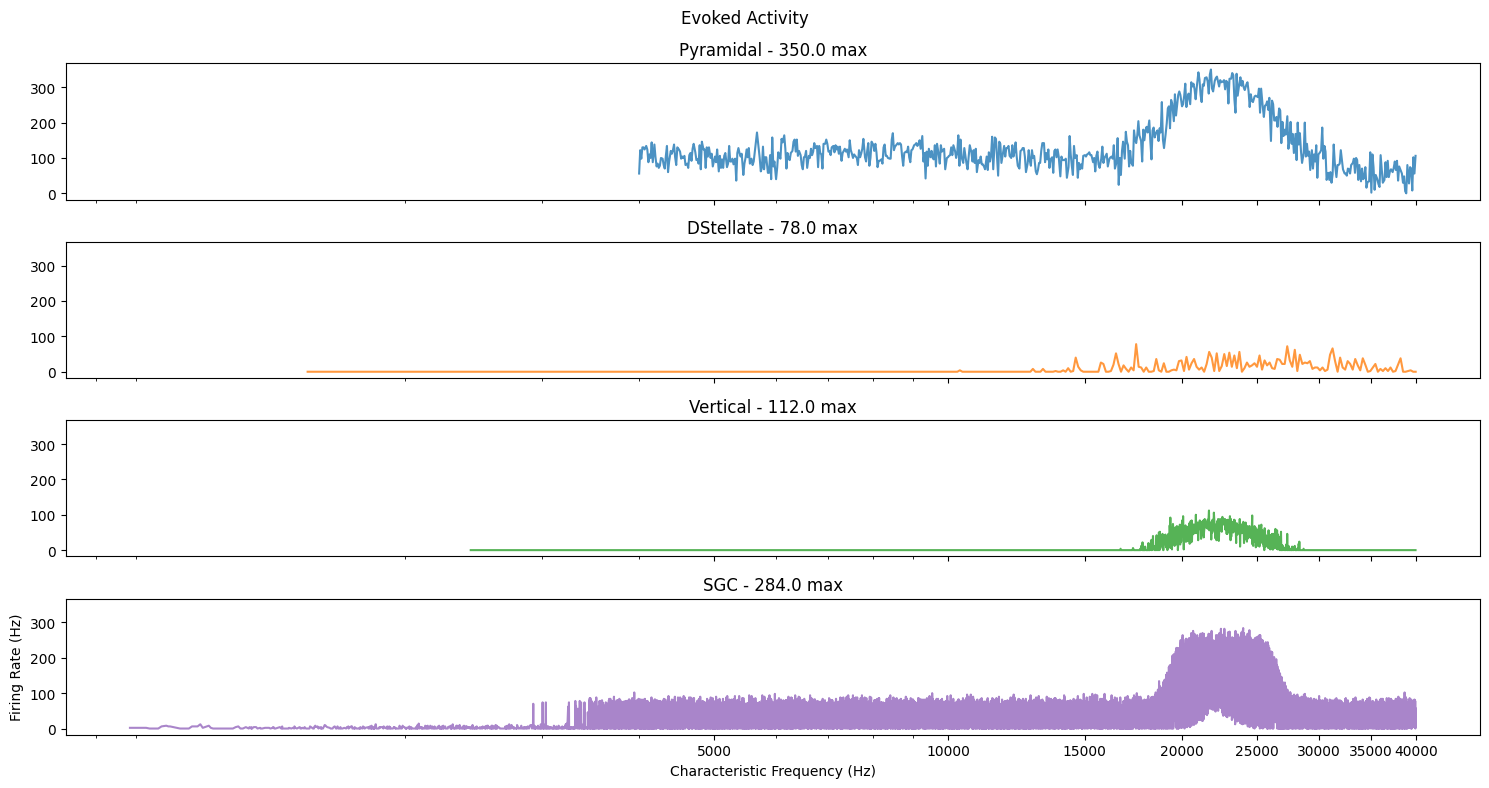

In [8]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(input_freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(input_freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(input_freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['evoked_rates']['tuberculoventral'][1][(input_freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(input_freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['evoked_rates']['sgc'][1][(input_freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Evoked Activity')
fig.tight_layout()

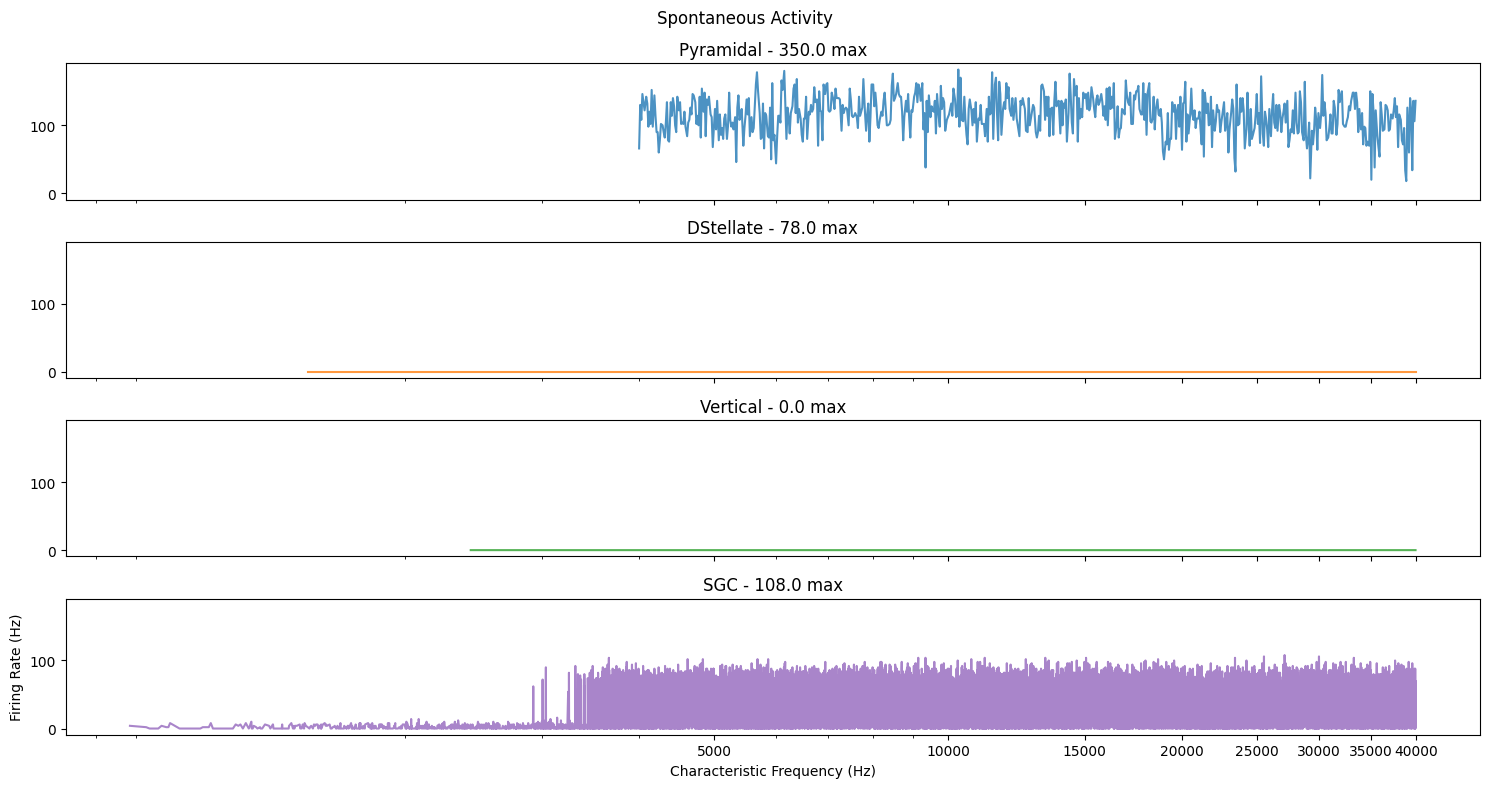

In [9]:
fig, axs = plt.subplots(4,1,figsize=(15,8), sharex=True, sharey=True)
axs = axs.ravel()

axs[0].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(input_freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(input_freq,level)], 
            color=colors['pyramidal'], zorder=13, alpha=0.8, label='pyramidal')
axs[0].set_title(f"Pyramidal - {np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)])} max")     
# axs[0].legend(loc='upper right')

axs[1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(input_freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(input_freq,level)], 
            color=colors['dstellate'], zorder=13, alpha=0.8, label='dstellate')
axs[1].set_title(f"DStellate - {np.max(norm_data_frs['evoked_rates']['dstellate'][1][(input_freq,level)])} max")
# axs[1].legend(loc='upper right')

axs[2].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(input_freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(input_freq,level)], 
            color=colors['vertical'], zorder=13, alpha=0.8, label='vertical')
axs[2].set_title(f"Vertical - {np.max(norm_data_frs['spont_rates']['tuberculoventral'][1][(input_freq,level)])} max")
# axs[2].legend(loc='upper right')

axs[3].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(input_freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(input_freq,level)], 
            color=colors['sgc'], zorder=13, alpha=0.8, label='sgc')
axs[3].set_title(f"SGC - {np.max(norm_data_frs['spont_rates']['sgc'][1][(input_freq,level)])} max")
# axs[3].legend(loc='upper right')

axs[-1].set_xlabel('Characteristic Frequency (Hz)')
axs[-1].set_ylabel('Firing Rate (Hz)')

axs[0].set_xscale('log')
axs[0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].xaxis.set_major_formatter(ScalarFormatter())

fig.suptitle('Spontaneous Activity')
fig.tight_layout()

## Hearing Loss @ 15kHz

In [10]:
loss_limit = 15000
input_freq = 22000

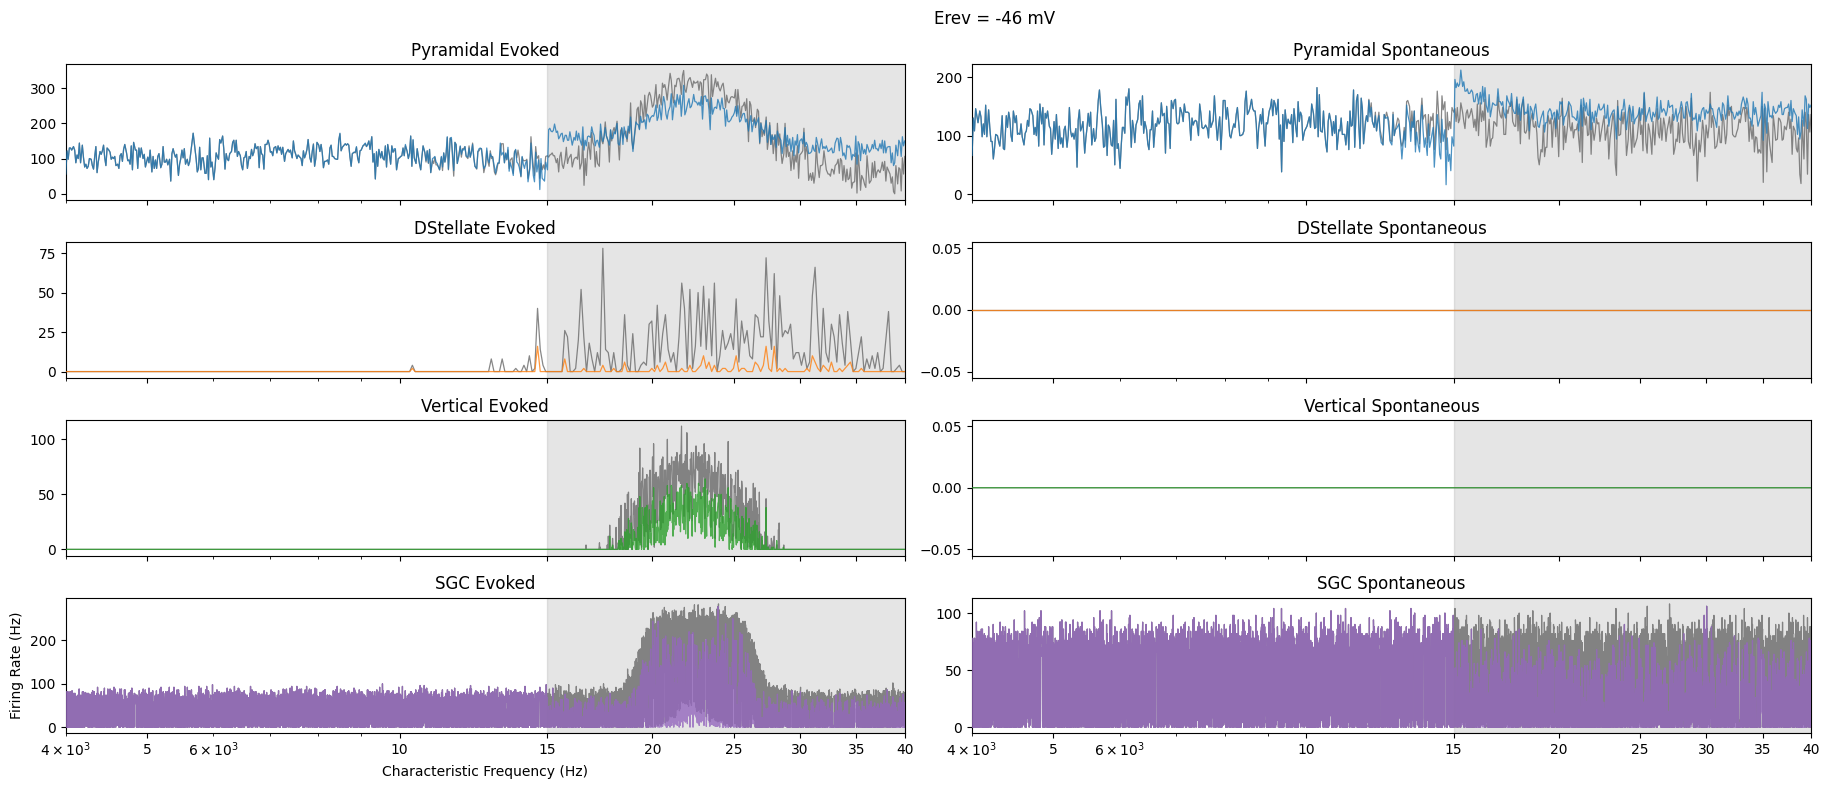

In [12]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(input_freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

# hfs = np.arange(1,2.1,0.05)
# hfs = np.array([1, 1.2, 1.4, 1.6, 1.8, 2])
# hfs = [f"{float(hf):.1f}" if float(hf).is_integer() else f"{hf:g}" for hf in hfs]
erevs = np.arange(-60, -39, 2)
hf = 1.0
# hfs[-2] = '2.0'

erevs = [-46]

for erev in erevs:

    fig, axs = plt.subplots(4,2,figsize=(20,8), sharex=True)  # sharey=True)

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN-Erev-{erev*-1}')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    axs[0,0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(input_freq,level)]], data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,0].set_title(f"Pyramidal Evoked")
    axs[0,1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(input_freq,level)]], data_frs['spont_rates']['pyramidal'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
    axs[0,1].set_title(f"Pyramidal Spontaneous")

    axs[1,0].plot(ds_cfs[data_frs['evoked_rates']['dstellate'][0][(input_freq,level)]], data_frs['evoked_rates']['dstellate'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,0].set_title(f"DStellate Evoked")
    axs[1,1].plot(ds_cfs[data_frs['spont_rates']['dstellate'][0][(input_freq,level)]], data_frs['spont_rates']['dstellate'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['dstellate'])
    axs[1,1].set_title(f"DStellate Spontaneous")

    axs[2,0].plot(vert_cfs[data_frs['evoked_rates']['tuberculoventral'][0][(input_freq,level)]], data_frs['evoked_rates']['tuberculoventral'][1][(input_freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,0].set_title(f"Vertical Evoked")
    axs[2,1].plot(vert_cfs[data_frs['spont_rates']['tuberculoventral'][0][(input_freq,level)]], data_frs['spont_rates']['tuberculoventral'][1][(input_freq,level)], 
                    zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['vertical'])
    axs[2,1].set_title(f"Vertical Spontaneous")

    axs[3,0].plot(sgc_cfs[data_frs['evoked_rates']['sgc'][0][(input_freq,level)]], data_frs['evoked_rates']['sgc'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,0].set_title(f"SGC Evoked")
    axs[3,1].plot(sgc_cfs[data_frs['spont_rates']['sgc'][0][(input_freq,level)]], data_frs['spont_rates']['sgc'][1][(input_freq,level)], 
                zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['sgc'])
    axs[3,1].set_title(f"SGC Spontaneous")


    axs[0,0].plot(pyr_cfs[norm_data_frs['evoked_rates']['pyramidal'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[0,1].plot(pyr_cfs[norm_data_frs['spont_rates']['pyramidal'][0][(input_freq,level)]], norm_data_frs['spont_rates']['pyramidal'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9, label='normal')
    axs[1,0].plot(ds_cfs[norm_data_frs['evoked_rates']['dstellate'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['dstellate'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[1,1].plot(ds_cfs[norm_data_frs['spont_rates']['dstellate'][0][(input_freq,level)]], norm_data_frs['spont_rates']['dstellate'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,0].plot(vert_cfs[norm_data_frs['evoked_rates']['tuberculoventral'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['tuberculoventral'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[2,1].plot(vert_cfs[norm_data_frs['spont_rates']['tuberculoventral'][0][(input_freq,level)]], norm_data_frs['spont_rates']['tuberculoventral'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,0].plot(sgc_cfs[norm_data_frs['evoked_rates']['sgc'][0][(input_freq,level)]], norm_data_frs['evoked_rates']['sgc'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)
    axs[3,1].plot(sgc_cfs[norm_data_frs['spont_rates']['sgc'][0][(input_freq,level)]], norm_data_frs['spont_rates']['sgc'][1][(input_freq,level)], 
                color='dimgrey', zorder=2, alpha=0.8, linewidth=0.9)

    axs[-1,0].set_xlabel('Characteristic Frequency (Hz)')
    axs[-1,0].set_ylabel('Firing Rate (Hz)')

    # axs[0].set_xlim(29000,40000)
    # axs[0].set_ylim(top=200)

    for ax in axs.ravel():
        ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)

    # for i in range(1,4):
    # axs[0,0].set_xscale('log')
    # axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    # axs[0,0].xaxis.set_major_formatter(ScalarFormatter())

    axs[0,0].set_xscale('log')
    axs[0,0].xaxis.set_major_formatter(ScalarFormatter())
    axs[0,0].set_xticks([5000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
    axs[0,0].set_xticklabels([5, 10, 15, 20, 25, 30, 35, 40])
    axs[0,0].set_xlim([4000, 40000])

    axs[0,1].set_ylim(bottom=-10)
    # axs[0,0].set_xlim([loss_limit-3000, 40000])

    # handles, labels = axs[0,1].get_legend_handles_labels()
    # fig.legend(handles, labels, title='Cihc', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

    fig.suptitle(f'Erev = {erev} mV')
    fig.tight_layout(rect=[0,0,0.92,1])

    fig.savefig('PCA-hearing_loss-erev-46.png', bbox_inches='tight', dpi=300)
    fig.savefig('PCA-hearing_loss-erev-46.pdf', bbox_inches='tight', dpi=300)

In [12]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(input_freq//1e3)}kHz_{level}dB-{nreps}nreps'


cohc = 0.8
cihc = 0.8
sgn_loss = 50

hf = '1.0'
erev = '-46'

hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN-Erev{erev}')
data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
data_frs = pickle.load(open(data_path, 'rb'))

evoked peak at 15295.125081497566
spont peak at 15295.125081497566


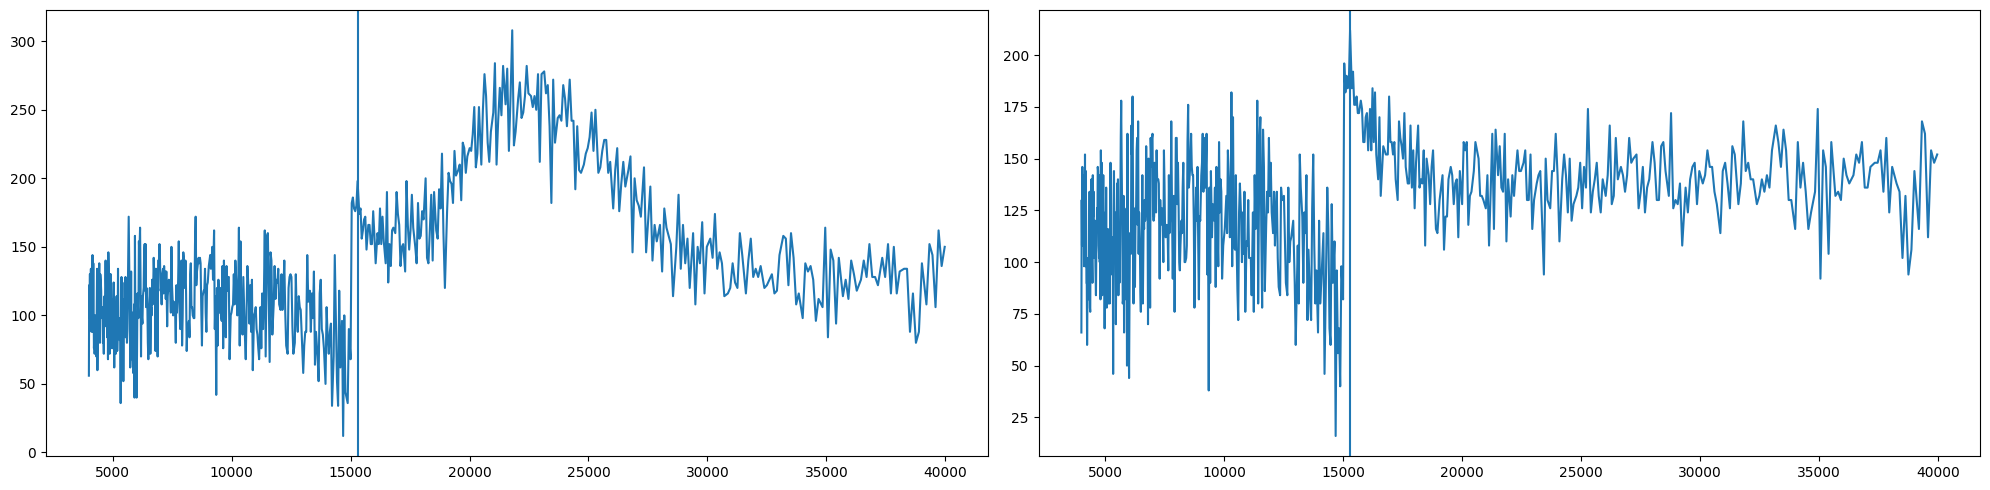

In [13]:
fig, axs = plt.subplots(1,2,figsize=(20,5))
pyr_evoked_rates = data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)]
pyr_evoked_cfs = pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(input_freq,level)]]

pyr_spont_rates = data_frs['spont_rates']['pyramidal'][1][(input_freq,level)]
pyr_spont_cfs = pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(input_freq,level)]]

axs[0].plot(pyr_evoked_cfs, pyr_evoked_rates)  #,zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
peak_freq = pyr_evoked_cfs[np.where((pyr_evoked_cfs > 10000) & (pyr_evoked_cfs < 18000))][np.argmax(pyr_evoked_rates[np.where((pyr_evoked_cfs > 10000) & (pyr_evoked_cfs < 18000))])]
axs[0].axvline(peak_freq)
print(f'evoked peak at {peak_freq}')

axs[1].plot(pyr_spont_cfs, pyr_spont_rates)  #,zorder=13, alpha=0.8, label=cihc, linewidth=0.9, color=colors['pyramidal'])
peak_freq = pyr_spont_cfs[np.where((pyr_spont_cfs > 10000) & (pyr_spont_cfs < 18000))][np.argmax(pyr_spont_rates[np.where((pyr_spont_cfs > 10000) & (pyr_spont_cfs < 18000))])]
axs[1].axvline(peak_freq)
print(f'spont peak at {peak_freq}')

fig.tight_layout()

In [14]:
erevs[::-1]

array([-40, -42, -44, -46, -48, -50, -52, -54, -56, -58, -60])

-60 0.3940384615384147
-58 0.3788461538461405
-56 0.23826923076921958
-54 0.30519230769229466
-52 9.616249999999454
-50 22.49692307692179
-48 35.67874999999796
-46 50.68278846153555
-44 72.50432692307265
-42 79.31644230768768
-40 81.04355769230293


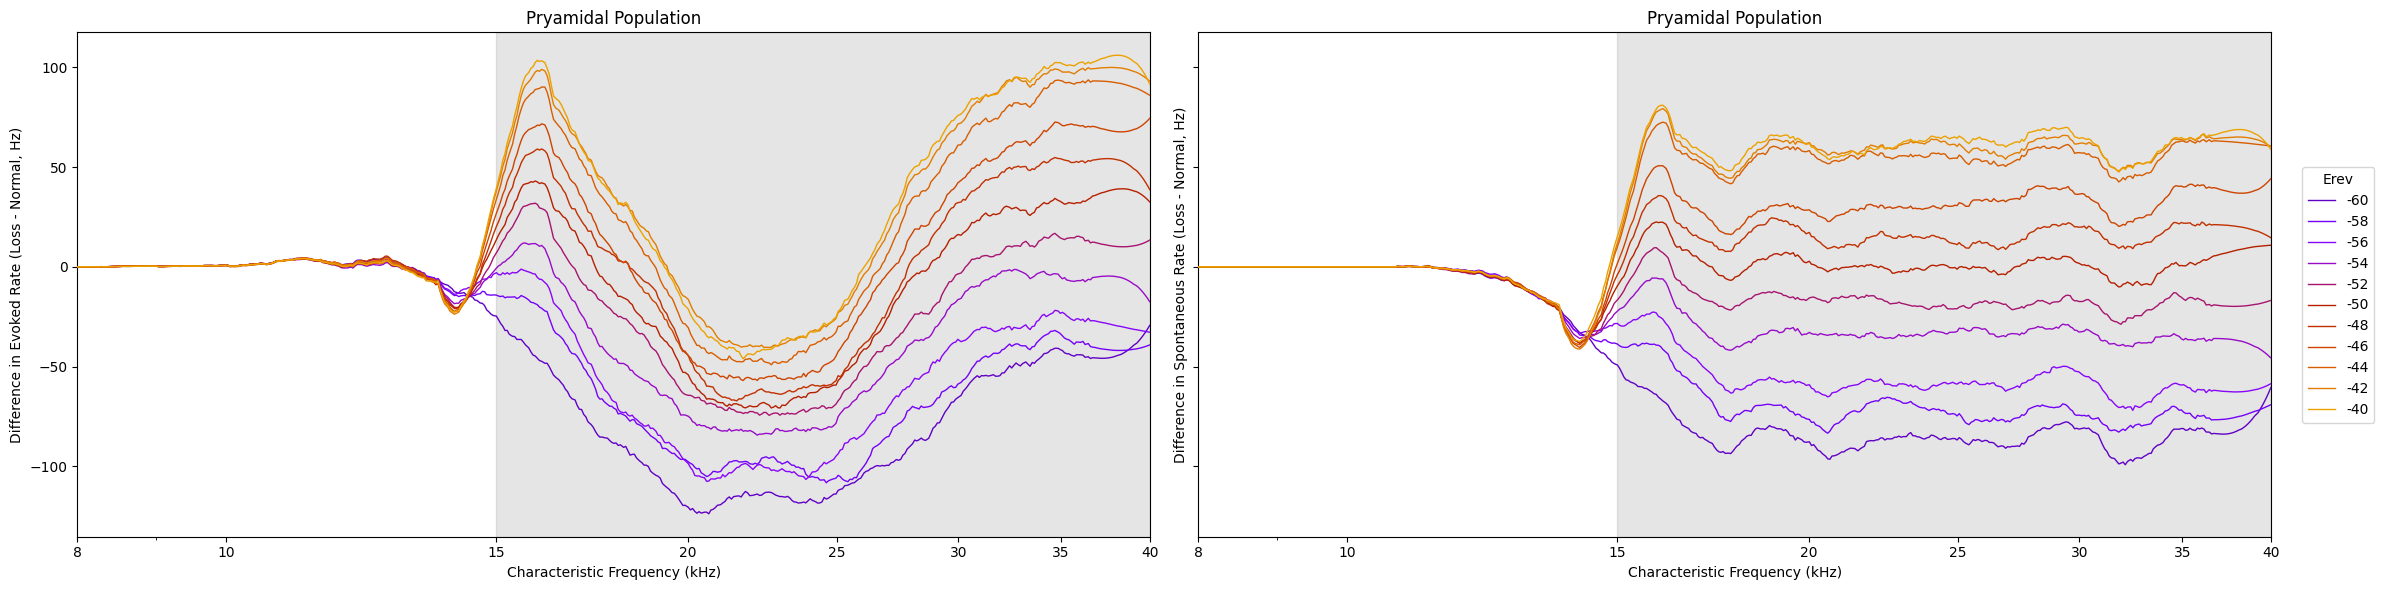

In [14]:
cohc = 0.8
cihc = 0.8
sgn_loss = 50

hf = 1.0
erevs = np.arange(-60, -39, 2)

erev_colors = mpl.colormaps['gnuplot'](np.linspace(0,1,len(erevs)+4))

fig, axs = plt.subplots(1,2,figsize=(25,6), sharex=True, sharey=True)

norm_evoked = norm_data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)]
norm_spont = norm_data_frs['spont_rates']['pyramidal'][1][(input_freq,level)]

filter_rates = True
wl = 50

if filter_rates:
    norm_evoked = savgol_filter(norm_evoked, window_length=wl, polyorder=3)
    norm_spont = savgol_filter(norm_spont, window_length=wl, polyorder=3)


# hfs[-2] = '2.0'

for i, erev in enumerate(erevs):

    sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(input_freq//1e3)}kHz_{level}dB-{nreps}nreps'

    hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN-Erev-{erev*-1}')
    data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx{hf}")
    data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
    data_frs = pickle.load(open(data_path, 'rb'))

    pyr_evoked = data_frs['evoked_rates']['pyramidal'][1][(input_freq,level)]
    pyr_spont = data_frs['spont_rates']['pyramidal'][1][(input_freq,level)]

    if filter_rates:
        pyr_evoked = savgol_filter(pyr_evoked, window_length=wl, polyorder=3)
        pyr_spont = savgol_filter(pyr_spont, window_length=wl, polyorder=3)

    print(erev, np.max(pyr_spont - norm_spont))
    
    axs[0].plot(pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(input_freq,level)]], pyr_evoked - norm_evoked, # savgol_filter(, window_length=wl, polyorder=3), 
                zorder=13, alpha=1.0,  linewidth=1.0, label=erev, color=erev_colors[i+2])   # color=colors['pyramidal'])
    # axs[0].set_title(f"Evoked Difference from Normal")
    axs[1].plot(pyr_cfs[data_frs['spont_rates']['pyramidal'][0][(input_freq,level)]], pyr_spont - norm_spont, # savgol_filter(, window_length=wl, polyorder=3), 
                zorder=13, alpha=1.0, linewidth=1.0, label=erev, color=erev_colors[i+2])   # color=colors['pyramidal'])
    # axs[1].set_title(f"Spontaneous Difference from Normal")

for ax in axs.ravel():
    # ax.axhline(0, color='k', linestyle='--', linewidth=0.9, alpha=0.5, zorder=2)
    ax.axvspan(loss_limit,40000, color='grey', alpha=0.2, zorder=1)
    ax.set_xlabel('Characteristic Frequency (kHz)')
    ax.set_title('Pryamidal Population')

axs[0].set_xscale('log')
axs[0].xaxis.set_major_formatter(ScalarFormatter())

axs[0].set_xticks([8000, 10000, 15000, 20000, 25000, 30000, 35000, 40000])
axs[0].set_xticklabels([8, 10, 15, 20, 25, 30, 35, 40])
axs[0].set_xlim([loss_limit-7000, 40000])

axs[0].set_ylabel('Difference in Evoked Rate (Loss - Normal, Hz)')
axs[1].set_ylabel('Difference in Spontaneous Rate (Loss - Normal, Hz)')

handles, labels = axs[1].get_legend_handles_labels()
fig.legend(handles, labels, title='Erev', loc='center left', bbox_to_anchor=(0.92,0.5), frameon=True)

# fig.suptitle(f'HF = {hf}')
fig.tight_layout(rect=[0,0,0.92,1])
fig.savefig('PCA-erev_tuning_diff.png', bbox_inches='tight', dpi=300)
fig.savefig('PCA-erev_tuning_diff.pdf', bbox_inches='tight', dpi=300)

In [18]:
labels

['-60', '-58', '-56', '-54', '-52', '-50', '-48', '-46', '-44', '-42', '-40']